# 04 · Contraste de H1: SARIMAX con el rol de Gobierno como variable exógena

**Hipótesis (Entrega 2).** *H1: las intervenciones de las familias políticas presentan, en promedio, puntuaciones de sentimiento más negativas durante los periodos en los que ejercen la oposición que durante aquellos en los que forman parte del Gobierno (2016–2026).* H0: no hay diferencia sistemática.

**Idea.** En el notebook 03 vimos que el tono mensual es **muy persistente** (AR ≈ 0,9) y que su nivel cambia por factores externos a la serie. Aquí se mete uno de esos factores, el rol de cada partido, como **variable exógena** de un SARIMAX:

$$y_t = a + \beta\,\text{gobierno}_t + \gamma\,t + u_t, \qquad u_t \sim \text{ARMA}(1,1)$$

- $y_t$: sentimiento medio mensual del partido.
- $\text{gobierno}_t$: 1 si el partido está en el Gobierno ese mes (notebook 01).
- $t$: tendencia lineal (en años), para separar el cambio de rol de la **caída general del tono** vista en el notebook 02.
- $u_t$: errores ARMA(1,1). Recogen la persistencia; sin ellos (una regresión MCO normal) los errores estándar serían demasiado pequeños porque los meses no son independientes.

**H1 se apoya si $\beta > 0$ y su intervalo de confianza al 95 % no incluye el 0.**

Solo hay tres partidos que cambian de rol: **PP** (Gobierno → oposición en 2018), **PSOE** (oposición → Gobierno en 2018) y **Podemos-UP-Sumar** (oposición → Gobierno en 2020). VOX y Cs están siempre en la oposición, así que no aportan variación del rol.

**Contrastes, de más simple a más exigente:**
1. SARIMAX por partido, con y sin tendencia, con todas las intervenciones y solo con diputados (sin ministros).
2. Brecha PP − PSOE: los cambios comunes a la Cámara se cancelan.
3. Placebo: cambios de Gobierno ficticios donde no hubo ninguno.
4. Panel con efectos fijos de partido y de mes (diferencias en diferencias), como comprobación complementaria.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, RESULTS = ROOT / "data", ROOT / "results"

COLOR = {"PP": "#1d5fa8", "PSOE": "#d62728", "Podemos-UP-Sumar": "#6a3d9a", "VOX": "#4daf4a", "Cs": "#ff7f0e"}
PARTIDOS = ["PP", "PSOE", "Podemos-UP-Sumar"]
VARIABLE = {"sentiment": "todas las intervenciones", "sentiment_diputados": "solo diputados"}

panel = pd.read_csv(DATA / "panel_partido_mes.csv")
panel["fecha"] = pd.to_datetime(panel.month)

def serie(partido, col):
    """Serie mensual de un partido (frecuencia MS, huecos como NaN) y su variable gobierno."""
    g = panel[panel.party == partido].set_index("fecha").asfreq("MS")
    return g[col], g.gobierno.astype(float)

for p in PARTIDOS:
    y, g = serie(p, "sentiment")
    print(f"{p:17s} {y.notna().sum()} meses con dato | {int(g[y.notna()].sum())} en el Gobierno, {int((1 - g[y.notna()]).sum())} en la oposición")

PP                104 meses con dato | 21 en el Gobierno, 83 en la oposición
PSOE              104 meses con dato | 83 en el Gobierno, 21 en la oposición
Podemos-UP-Sumar  104 meses con dato | 71 en el Gobierno, 33 en la oposición


## 1. SARIMAX por partido

La constante y la tendencia se pasan como columnas de `exog` (con `trend="n"`), así el modelo es exactamente una **regresión con errores ARMA** y los coeficientes se leen directamente. Los meses sin dato quedan como `NaN` y el filtro de Kalman los salta, igual que en el notebook 03.

Se ajustan 3 partidos × 2 variables (todas / solo diputados) × 2 especificaciones (sin / con tendencia). El orden ARMA(1,1) es el elegido en el notebook 03; como robustez también se ajusta un AR(1).

In [2]:
def regresores(g, tendencia):
    X = pd.DataFrame({"const": 1.0, "gobierno": g}, index=g.index)
    if tendencia:
        X["tendencia"] = np.arange(len(g)) / 12   # años desde el inicio
    return X

def ajustar_h1(y, X, order=(1, 0, 1)):
    return SARIMAX(y, exog=X, order=order, trend="n").fit(disp=False, maxiter=1000)

filas, modelos = [], {}
for col in VARIABLE:
    for p in PARTIDOS:
        y, g = serie(p, col)
        for tendencia in (False, True):
            for order in [(1, 0, 1), (1, 0, 0)]:
                fit = ajustar_h1(y, regresores(g, tendencia), order)
                lo, hi = fit.conf_int().loc["gobierno"]
                filas.append({"variable": VARIABLE[col], "partido": p,
                              "control": "tendencia" if tendencia else "ninguno",
                              "arma": f"ARMA{order[0], order[2]}",
                              "beta_gobierno": fit.params["gobierno"], "ic95_inf": lo, "ic95_sup": hi,
                              "p_valor": fit.pvalues["gobierno"],
                              "tendencia_anual": fit.params.get("tendencia", np.nan),
                              "ar1": fit.params["ar.L1"], "aic": fit.aic,
                              "ljung_box_p12": acorr_ljungbox(fit.resid.dropna(), lags=[12]).lb_pvalue.iloc[0]})
                modelos[(col, p, tendencia, order)] = fit

coef = pd.DataFrame(filas)
coef.to_csv(RESULTS / "04_coeficientes_gobierno.csv", index=False)
principal = coef[coef.arma == "ARMA(1, 1)"]
principal.round(4)

,variable,partido,control,arma,beta_gobierno,ic95_inf,ic95_sup,p_valor,tendencia_anual,ar1,aic,ljung_box_p12
0,todas las intervenciones,PP,ninguno,"ARMA(1, 1)",0.3915,0.3513,0.4317,0.0000,NaN,0.5245,-209.3674,0.9543
2,todas las intervenciones,PP,tendencia,"ARMA(1, 1)",0.3996,0.3457,0.4535,0.0000,0.0015,0.5527,-207.5543,0.9525
4,todas las intervenciones,PSOE,ninguno,"ARMA(1, 1)",0.1464,0.0994,0.1934,0.0000,NaN,-0.1875,-212.9619,0.5239
6,todas las intervenciones,PSOE,tendencia,"ARMA(1, 1)",0.1527,0.0881,0.2172,0.0000,-0.0012,-0.2912,-211.0270,0.5341
8,todas las intervenciones,Podemos-UP-Sumar,ninguno,"ARMA(1, 1)",0.0887,0.0498,0.1276,0.0000,NaN,-0.4046,-206.0662,0.8524
10,todas las intervenciones,Podemos-UP-Sumar,tendencia,"ARMA(1, 1)",0.1211,0.0588,0.1834,0.0001,-0.0061,-0.4596,-205.4113,0.7226
12,solo diputados,PP,ninguno,"ARMA(1, 1)",0.2873,0.2436,0.3310,0.0000,NaN,-0.2412,-206.7972,0.7290
14,solo diputados,PP,tendencia,"ARMA(1, 1)",0.2938,0.2311,0.3564,0.0000,0.0012,-0.3783,-204.8344,0.7239
16,solo diputados,PSOE,ninguno,"ARMA(1, 1)",0.1184,0.0807,0.1561,0.0000,NaN,0.6486,-195.2345,0.2382
18,solo diputados,PSOE,tendencia,"ARMA(1, 1)",0.1591,0.1165,0.2017,0.0000,-0.0064,0.8095,-197.0201,0.2159


**Cómo leer la tabla.** `beta_gobierno` es la diferencia de sentimiento entre estar en el Gobierno y en la oposición, para un mismo partido, una vez descontadas la persistencia (ARMA) y, si se indica, la tendencia. Un valor de 0,10 equivale a un tercio de la desviación típica de una intervención individual (0,29, notebook 02).

`ljung_box_p12` > 0,05 indica que no queda autocorrelación en los residuos, es decir, que la parte ARMA ha recogido la dependencia temporal y los intervalos de confianza son fiables en ese aspecto.

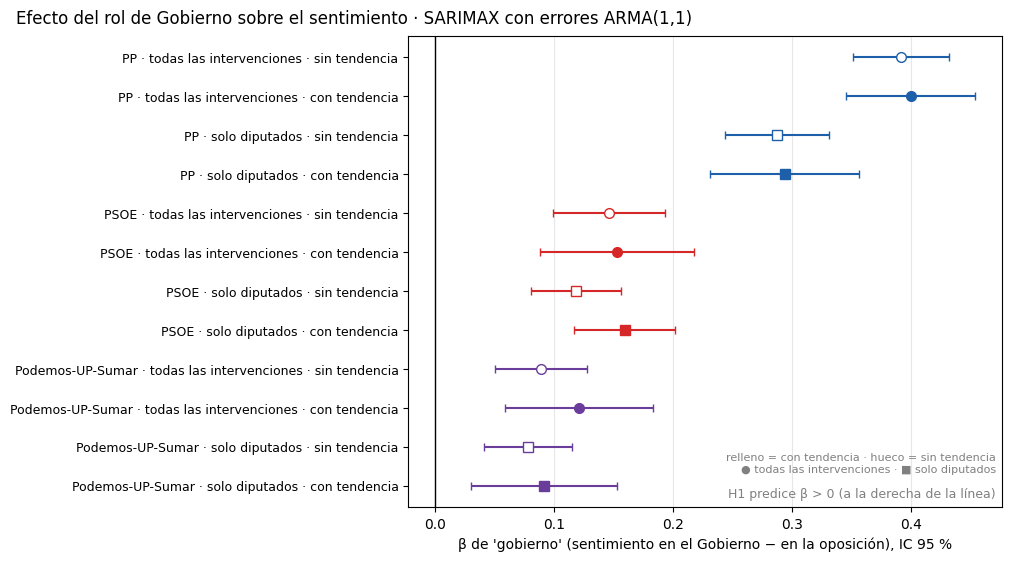

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
orden = [(p, v, c) for p in PARTIDOS for v in VARIABLE.values() for c in ("ninguno", "tendencia")]
etiquetas = []
for i, (p, v, c) in enumerate(orden):
    r = principal[(principal.partido == p) & (principal.variable == v) & (principal.control == c)].iloc[0]
    yy = len(orden) - 1 - i
    ax.errorbar(r.beta_gobierno, yy, xerr=[[r.beta_gobierno - r.ic95_inf], [r.ic95_sup - r.beta_gobierno]],
                fmt="o" if v == "todas las intervenciones" else "s", color=COLOR[p],
                mfc=COLOR[p] if c == "tendencia" else "white", capsize=3, ms=7)
    etiquetas.append((yy, f"{p} · {v} · {'con' if c == 'tendencia' else 'sin'} tendencia"))
ax.set_yticks([e[0] for e in etiquetas], [e[1] for e in etiquetas], fontsize=9)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("β de 'gobierno' (sentimiento en el Gobierno − en la oposición), IC 95 %")
fig.suptitle("Efecto del rol de Gobierno sobre el sentimiento · SARIMAX con errores ARMA(1,1)", x=.01, ha="left")
ax.text(.99, .07, "relleno = con tendencia · hueco = sin tendencia\n● todas las intervenciones · ■ solo diputados", transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="gray")
ax.text(.99, .02, "H1 predice β > 0 (a la derecha de la línea)", transform=ax.transAxes, ha="right", fontsize=9, color="gray")
ax.grid(axis="x", alpha=.3)
fig.savefig(RESULTS / "04_coeficientes_gobierno.png", dpi=160)
plt.show()

**Interpretación.**
- Los **12 coeficientes principales son positivos** y ninguno de sus intervalos toca el 0: los tres partidos que cambian de rol hablan con un tono más positivo cuando gobiernan.
- **La tendencia no se come el efecto.** Al añadirla, β apenas cambia (y en Podemos incluso sube algo). La caída general del tono no explica el salto; lo que explica el salto es el cambio de rol.
- **Quitar a los ministros reduce el efecto, pero no lo elimina.** En el PP pasa de ≈ 0,40 a ≈ 0,29, porque en 2016–2018 dos de cada tres intervenciones del PP eran de ministros (notebook 01). Aun así, los diputados rasos del PP también se vuelven bastante más negativos al pasar a la oposición. El efecto es, por tanto, del **rol del partido** y no solo del cargo de quien habla.
- **El tamaño es asimétrico:** grande en el PP, moderado en el PSOE (≈ 0,15) y pequeño en Podemos (≈ 0,09–0,13). Podemos entra en un Gobierno de coalición como socio menor y en el mismo momento que la pandemia; su discurso más crítico se mantiene en parte.
- La tabla completa incluye también el AR(1): los coeficientes son prácticamente iguales, así que el resultado no depende del orden ARMA elegido.

**Dos hallazgos que conectan con los notebooks 02 y 03:**
- **La tendencia por partido es prácticamente nula** (entre −0,006 y +0,002 por año) una vez que se incluye el rol. La caída del tono global (−0,014 por año, notebook 02) no es un empeoramiento de cada partido: sale de los cambios de rol y de la composición (la entrada de VOX, muy negativo, en 2020).
- **La "persistencia" casi desaparece.** En el notebook 03 la serie global tenía un AR ≈ 0,90. Aquí, con el rol como regresor, los coeficientes AR quedan entre −0,46 y 0,81, y la mayoría lejos de 1. Buena parte de esa memoria aparente era el salto de nivel de 2018. Confirma lo que sugería el ADF del notebook 02: el cambio estructural imitaba una raíz unitaria.

## 2. Qué significa β en la serie: observado frente a contrafactual

Para cada partido (modelo principal: todas las intervenciones, con tendencia) se dibuja:
- los puntos mensuales observados;
- la **parte estructural** del modelo, $a + \beta\,\text{gobierno}_t + \gamma t$, es decir, el nivel que explica el modelo sin el ruido ARMA;
- el **contrafactual**: la misma recta si el partido hubiera tenido el rol contrario. La distancia entre las dos líneas es β.

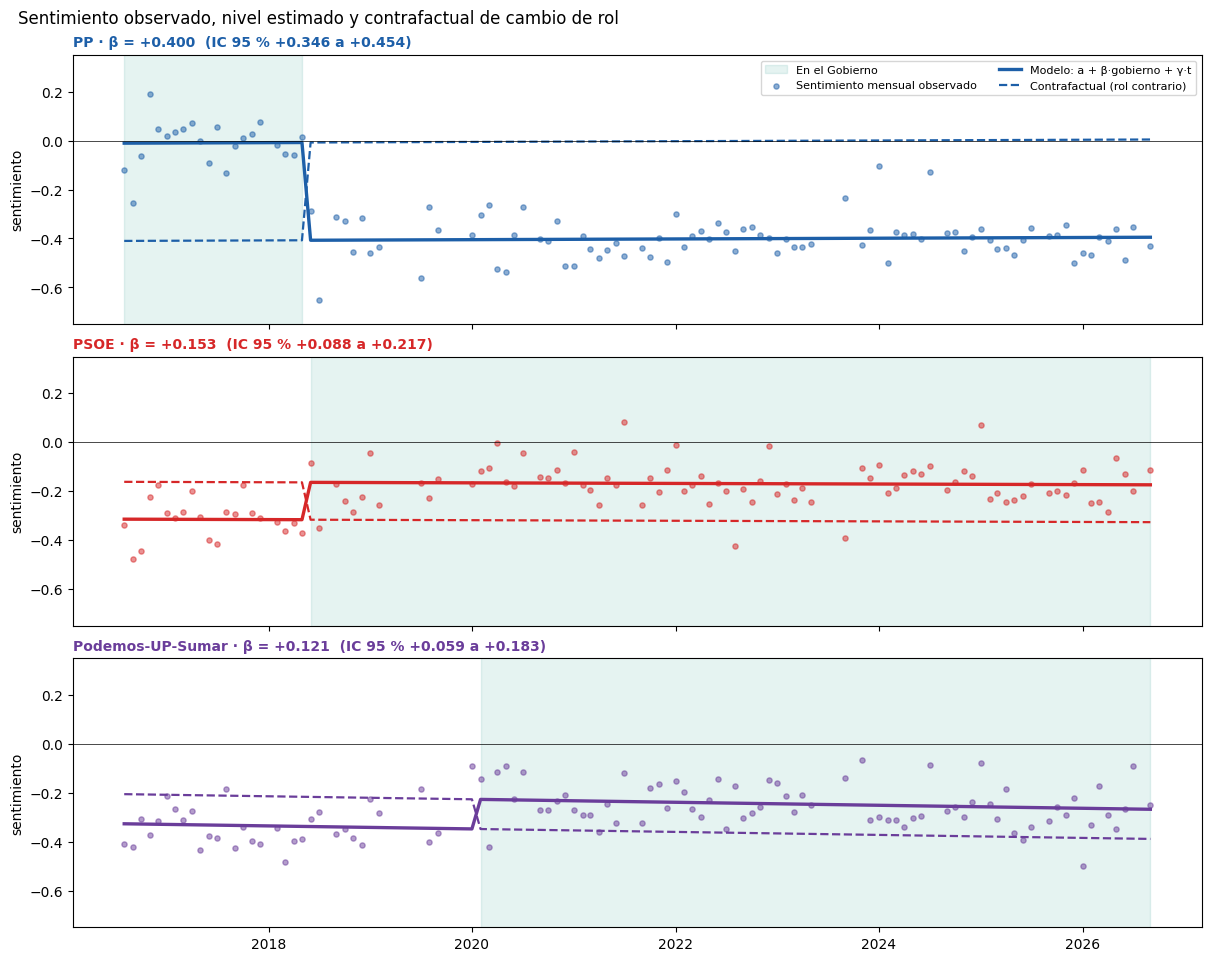

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9.5), sharex=True, layout="constrained")
for ax, p in zip(axes, PARTIDOS):
    y, g = serie(p, "sentiment")
    fit = modelos[("sentiment", p, True, (1, 0, 1))]
    X = regresores(g, True)
    b = fit.params[X.columns]
    estructural = X @ b
    contrafactual = X.assign(gobierno=1 - X.gobierno) @ b
    ax.fill_between(g.index, -1, 1, where=g == 1, step="mid", color="#2a9d8f", alpha=.12, label="En el Gobierno")
    ax.scatter(y.index, y, s=14, color=COLOR[p], alpha=.5, label="Sentimiento mensual observado")
    ax.plot(estructural.index, estructural, color=COLOR[p], lw=2.4, label="Modelo: a + β·gobierno + γ·t")
    ax.plot(contrafactual.index, contrafactual, color=COLOR[p], lw=1.6, ls="--", label="Contrafactual (rol contrario)")
    ax.axhline(0, color="black", lw=.5)
    ax.set_ylim(-.75, .35)
    ax.set_title(f"{p} · β = {b['gobierno']:+.3f}  (IC 95 % {fit.conf_int().loc['gobierno', 0]:+.3f} a {fit.conf_int().loc['gobierno', 1]:+.3f})",
                 loc="left", fontsize=10, color=COLOR[p], fontweight="bold")
    ax.set_ylabel("sentimiento")
axes[0].legend(loc="upper right", ncol=2, fontsize=8)
fig.suptitle("Sentimiento observado, nivel estimado y contrafactual de cambio de rol", x=.01, ha="left")
fig.savefig(RESULTS / "04_contrafactual_partidos.png", dpi=160)
plt.show()

**Interpretación.** En el PP el salto de 2018 es la característica dominante de toda la serie: el contrafactual "PP en el Gobierno después de 2018" estaría unas 0,4 unidades por encima, en torno al nivel de 2016–2018. En el PSOE el salto es visible pero se superpone a la caída general. En Podemos el efecto es el más pequeño y los datos mensuales son más ruidosos (menos intervenciones por mes).

## 3. Brecha PP − PSOE

Cualquier cosa que afecte a toda la Cámara a la vez (pandemia, crispación general, cambios del corpus) desplaza por igual al PP y al PSOE y **se cancela en la diferencia**. Como en junio de 2018 los dos cambian de rol en sentidos opuestos, el modelo sobre la brecha es el contraste más limpio:

$$\text{brecha}_t = \text{PP}_t - \text{PSOE}_t = a + \delta\,\text{PP en el Gobierno}_t + \gamma t + u_t$$

Si el efecto del rol es parecido en los dos partidos, $\delta \approx 2\beta$.

In [5]:
ancho = panel.pivot(index="fecha", columns="party", values="sentiment").asfreq("MS")
brecha = (ancho["PP"] - ancho["PSOE"]).rename("brecha")
_, pp_gob = serie("PP", "sentiment")

filas_b = []
for tendencia in (False, True):
    for order in [(1, 0, 1), (1, 0, 0)]:
        Xb = regresores(pp_gob, tendencia)
        fit_b = ajustar_h1(brecha, Xb, order)
        lo, hi = fit_b.conf_int().loc["gobierno"]
        filas_b.append({"control": "tendencia" if tendencia else "ninguno", "arma": f"ARMA{order[0], order[2]}",
                        "delta_pp_gobierno": fit_b.params["gobierno"], "ic95_inf": lo, "ic95_sup": hi,
                        "p_valor": fit_b.pvalues["gobierno"],
                        "ljung_box_p12": acorr_ljungbox(fit_b.resid.dropna(), lags=[12]).lb_pvalue.iloc[0]})
        if tendencia and order == (1, 0, 1):
            fit_brecha, X_brecha = fit_b, Xb
tabla_brecha = pd.DataFrame(filas_b)
tabla_brecha.to_csv(RESULTS / "04_brecha_modelo.csv", index=False)
tabla_brecha.round(4)

,control,arma,delta_pp_gobierno,ic95_inf,ic95_sup,p_valor,ljung_box_p12
0,ninguno,"ARMA(1, 1)",0.5351,0.4672,0.6030,0.0,0.7656
1,ninguno,"ARMA(1, 0)",0.5352,0.4690,0.6013,0.0,0.8067
2,tendencia,"ARMA(1, 1)",0.5498,0.4648,0.6347,0.0,0.8066
3,tendencia,"ARMA(1, 0)",0.5497,0.4668,0.6326,0.0,0.8093


## 4. Prueba placebo

Un salto de nivel grande puede aparecer "por casualidad" en una serie persistente. Para comprobarlo se inventan **cambios de Gobierno ficticios** en el tramo en el que no hubo ninguno (julio de 2018 en adelante, siempre con PSOE en el Gobierno y PP en la oposición) y se reajusta el mismo modelo sobre la brecha. Si el método fuera propenso a encontrar efectos falsos, los δ placebo serían a menudo tan grandes como el real.

Las fechas ficticias van de 2019-07 a 2025-07, cada 3 meses, dejando al menos 12 meses de datos a cada lado.

In [6]:
tramo = brecha["2018-07":]
t_tramo = pd.Series(np.arange(len(tramo)) / 12, index=tramo.index)
placebos = []
for fecha in pd.date_range("2019-07-01", "2025-07-01", freq="3MS"):
    falso = pd.Series((tramo.index < fecha).astype(float), index=tramo.index)
    Xp = pd.DataFrame({"const": 1.0, "gobierno": falso, "tendencia": t_tramo})
    f = ajustar_h1(tramo, Xp)
    placebos.append({"fecha_ficticia": fecha.strftime("%Y-%m"), "delta": f.params["gobierno"],
                     "p_valor": f.pvalues["gobierno"]})
placebo = pd.DataFrame(placebos)
placebo.to_csv(RESULTS / "04_placebo.csv", index=False)
delta_real = fit_brecha.params["gobierno"]
print(f"δ real = {delta_real:.3f}")
print(f"δ placebo: media {placebo.delta.mean():+.3f}, |δ| máximo {placebo.delta.abs().max():.3f}, "
      f"{(placebo.p_valor < .05).sum()} de {len(placebo)} con p < 0,05")
print(f"Placebos con |δ| ≥ δ real: {(placebo.delta.abs() >= abs(delta_real)).sum()} de {len(placebo)}")

δ real = 0.550
δ placebo: media -0.008, |δ| máximo 0.137, 4 de 25 con p < 0,05
Placebos con |δ| ≥ δ real: 0 de 25


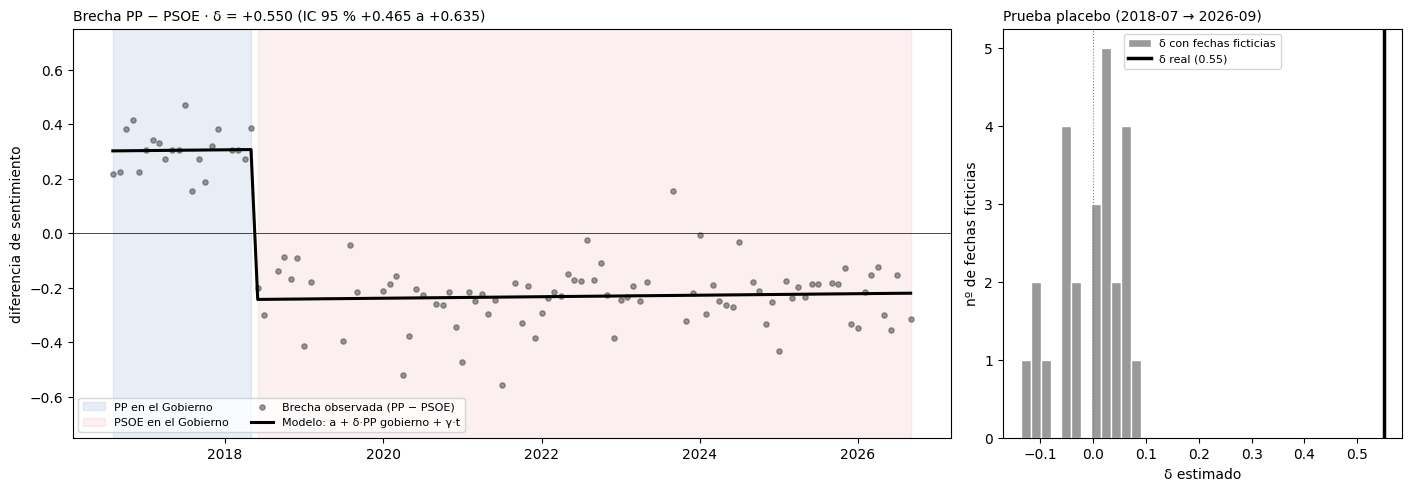

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout="constrained", gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
estr = X_brecha @ fit_brecha.params[X_brecha.columns]
ax.fill_between(pp_gob.index, -1, 1, where=pp_gob == 1, step="mid", color=COLOR["PP"], alpha=.10, label="PP en el Gobierno")
ax.fill_between(pp_gob.index, -1, 1, where=pp_gob == 0, step="mid", color=COLOR["PSOE"], alpha=.07, label="PSOE en el Gobierno")
ax.scatter(brecha.index, brecha, s=14, color="#555", alpha=.6, label="Brecha observada (PP − PSOE)")
ax.plot(estr.index, estr, color="black", lw=2.2, label="Modelo: a + δ·PP gobierno + γ·t")
ax.axhline(0, color="black", lw=.5)
ax.set_ylim(-.75, .75)
lo, hi = fit_brecha.conf_int().loc["gobierno"]
ax.set_title(f"Brecha PP − PSOE · δ = {delta_real:+.3f} (IC 95 % {lo:+.3f} a {hi:+.3f})", loc="left", fontsize=10)
ax.set_ylabel("diferencia de sentimiento")
ax.legend(loc="lower left", fontsize=8, ncol=2)

ax = axes[1]
ax.hist(placebo.delta, bins=12, color="#999", edgecolor="white", label="δ con fechas ficticias")
ax.axvline(delta_real, color="black", lw=2.5, label=f"δ real ({delta_real:.2f})")
ax.axvline(0, color="gray", lw=.8, ls=":")
ax.set_title("Prueba placebo (2018-07 → 2026-09)", loc="left", fontsize=10)
ax.set_xlabel("δ estimado"); ax.set_ylabel("nº de fechas ficticias")
ax.legend(fontsize=8, loc="upper center")
fig.savefig(RESULTS / "04_brecha_placebo.png", dpi=160)
plt.show()

**Interpretación.**
- La brecha PP − PSOE pasa de positiva (PP más positivo que el PSOE mientras gobierna) a negativa en cuanto se invierten los papeles, y el modelo estima δ ≈ 0,55. Es coherente con la suma de los efectos individuales (0,40 + 0,15).
- Como en la brecha se cancelan los factores comunes a toda la Cámara, este resultado no se puede atribuir a la crispación general ni a la pandemia.
- **Placebo:** con fechas ficticias, los δ son pequeños (|δ| ≤ 0,14) y se reparten alrededor de 0. Ninguno se acerca al δ real (0,55): el método no fabrica saltos de este tamaño en un tramo sin cambio de rol.
- Aun así, 4 de los 25 placebos salen con p < 0,05, más del 5 % que cabría esperar. Indica que los p-valores del SARIMAX son algo optimistas (fluctuaciones de nivel más lentas que lo que capta el ARMA(1,1)). Por eso conviene fijarse en el **tamaño** del efecto frente a la distribución placebo, no solo en el p-valor. En ese criterio el resultado real queda muy lejos de cualquier placebo.

## 5. Comprobación complementaria: panel con efectos fijos

Por último, un modelo de panel con los cinco partidos:

$$y_{p,t} = \alpha_p + \lambda_t + \beta\,\text{gobierno}_{p,t} + \varepsilon_{p,t}$$

- $\alpha_p$: un nivel propio para cada partido (efecto fijo de partido).
- $\lambda_t$: un efecto para **cada mes**, que absorbe todo lo común a la Cámara ese mes. VOX y Cs, siempre en la oposición, sirven aquí de grupo de control.
- β se estima a partir de cómo cambia un partido **respecto a los demás** al cambiar de rol (lógica de diferencias en diferencias).

No es un modelo de series temporales, sino un contraste con supuestos distintos al SARIMAX. Los errores estándar se agrupan por mes (correlación entre partidos dentro del mismo mes). No corrigen la autocorrelación dentro de cada partido, así que el intervalo es algo optimista.

In [8]:
filas_fe = []
for col in VARIABLE:
    d = panel[panel[col].notna()].copy()
    m = smf.ols(f"{col} ~ gobierno + C(party) + C(month)", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d.month.astype("category").cat.codes})
    lo, hi = m.conf_int().loc["gobierno"]
    filas_fe.append({"variable": VARIABLE[col], "beta_gobierno": m.params["gobierno"],
                     "ic95_inf": lo, "ic95_sup": hi, "p_valor": m.pvalues["gobierno"], "n_obs": int(m.nobs)})
efectos_fijos = pd.DataFrame(filas_fe)
efectos_fijos.to_csv(RESULTS / "04_panel_efectos_fijos.csv", index=False)
efectos_fijos.round(4)

,variable,beta_gobierno,ic95_inf,ic95_sup,p_valor,n_obs
0,todas las intervenciones,0.2335,0.2045,0.2624,0.0,416
1,solo diputados,0.1806,0.1537,0.2075,0.0,414


El panel da un β común de ≈ 0,23 con todas las intervenciones y ≈ 0,18 con solo diputados, ambos con intervalos lejos del 0. Es una media de los tres partidos que cambian de rol y queda entre el efecto del PSOE/Podemos y el del PP, como cabía esperar.

## 6. Veredicto sobre H1

In [9]:
resumen = pd.concat([
    principal[principal.control == "tendencia"].assign(contraste="SARIMAX por partido + tendencia")
        [["contraste", "partido", "variable", "beta_gobierno", "ic95_inf", "ic95_sup", "p_valor"]],
    tabla_brecha[(tabla_brecha.control == "tendencia") & (tabla_brecha.arma == "ARMA(1, 1)")]
        .assign(contraste="Brecha PP − PSOE + tendencia (δ ≈ 2β)", partido="PP − PSOE", variable="todas las intervenciones")
        .rename(columns={"delta_pp_gobierno": "beta_gobierno"})
        [["contraste", "partido", "variable", "beta_gobierno", "ic95_inf", "ic95_sup", "p_valor"]],
    efectos_fijos.assign(contraste="Panel efectos fijos partido + mes", partido="los 5")
        [["contraste", "partido", "variable", "beta_gobierno", "ic95_inf", "ic95_sup", "p_valor"]],
], ignore_index=True)
resumen["apoya_H1"] = (resumen.ic95_inf > 0).map({True: "sí", False: "no"})
resumen.to_csv(RESULTS / "04_veredicto_h1.csv", index=False)
resumen.round(4)

,contraste,partido,variable,beta_gobierno,ic95_inf,ic95_sup,p_valor,apoya_H1
0,SARIMAX por partido + tendencia,PP,todas las intervenciones,0.3996,0.3457,0.4535,0.0000,sí
1,SARIMAX por partido + tendencia,PSOE,todas las intervenciones,0.1527,0.0881,0.2172,0.0000,sí
2,SARIMAX por partido + tendencia,Podemos-UP-Sumar,todas las intervenciones,0.1211,0.0588,0.1834,0.0001,sí
3,SARIMAX por partido + tendencia,PP,solo diputados,0.2938,0.2311,0.3564,0.0000,sí
4,SARIMAX por partido + tendencia,PSOE,solo diputados,0.1591,0.1165,0.2017,0.0000,sí
5,SARIMAX por partido + tendencia,Podemos-UP-Sumar,solo diputados,0.0912,0.0300,0.1525,0.0035,sí
6,Brecha PP − PSOE + tendencia (δ ≈ 2β),PP − PSOE,todas las intervenciones,0.5498,0.4648,0.6347,0.0000,sí
7,Panel efectos fijos partido + mes,los 5,todas las intervenciones,0.2335,0.2045,0.2624,0.0000,sí
8,Panel efectos fijos partido + mes,los 5,solo diputados,0.1806,0.1537,0.2075,0.0000,sí


**H1 queda apoyada** (se rechaza H0) dentro de 2016–2026: en todos los contrastes, el coeficiente del rol de Gobierno es positivo y su intervalo al 95 % excluye el 0.

- El efecto **sobrevive** a la persistencia del tono (errores ARMA), a la tendencia general negativa, a la exclusión de los ministros, a la diferencia PP − PSOE (que cancela los factores comunes), a la prueba placebo y a un panel con efectos fijos de mes.
- El efecto es **heterogéneo**: grande para el PP (≈ 0,40; ≈ 0,29 sin ministros), moderado para el PSOE (≈ 0,15) y pequeño para Podemos-UP-Sumar (≈ 0,09–0,13).

**Matices que hay que llevar a la memoria:**
1. **Pocos eventos.** Solo hay dos cambios de Gobierno (2018 y 2020) y tres partidos que cambian de rol. Es evidencia consistente, pero basada en muy pocas transiciones; no se puede generalizar más allá de este periodo.
2. **Asociación, no causalidad estricta.** Los contrastes descartan explicaciones concretas (tendencia, shocks comunes, cargo de ministro, saltos espurios), pero cualquier otra cosa que cambiara exactamente en junio de 2018 o enero de 2020 quedaría confundida con el rol.
3. **Medida del sentimiento.** RoBERTuito está entrenado con tuits; el tono parlamentario (ironía, fórmulas de cortesía) puede medirse con sesgo. Mientras ese sesgo no cambie con el rol, β no se ve afectado.
4. **Huecos y tamaño mensual.** Los meses con pocas intervenciones pesan igual que los demás en el SARIMAX; ponderar por nº de intervenciones es una mejora posible.